# Лабораторная работа №2
## Раздел 1.1: Исследование наборов данных (ФКГ и модуль позиционирования)
**Студент:** Мустафаев Музаффар


### Задание 1.1.1. Имена столбцов и целевые классы
Отдельно для каждого из наборов данных (ФКГ — 3 файла, модуль позиционирования) получить имена столбцов. В описание к ответу вывести имена столбцов с названиями классов.


In [1]:
# Ответ на задание 1.1.1: Имена столбцов и целевые переменные
print("=== Набор ФКГ (Фонокардиограммы) ===")
print("Столбцы wave.csv:", list(df_wave.columns[:5]), "...", list(df_wave.columns[-5:]))
print("Столбцы envelope.csv:", list(df_env.columns[:5]), "...", list(df_env.columns[-5:]))
print("Столбцы wes.csv:", list(df_wes.columns[:5]), "...", list(df_wes.columns[-5:]))
print("Целевой столбец ФКГ: 'Type' (классы: wave, fS2, fS1, mom)")

print("\n=== Набор с модуля позиционирования ===")
print("Метаданные столбцов:", list(df_pos.columns[:9]))
print("Сигнальные параметры (ускорения):", list(df_pos.columns[9:14]), "...", list(df_pos.columns[-5:]))
print("Целевой столбец: 'class_type' (классы схватов 1-9)")


=== Набор ФКГ (Фонокардиограммы) ===
Столбцы wave.csv: ['RecordName', 'Start', 'Stop', 'Duration', 'Type'] ... ['wave181', 'wave182', 'wave183', 'wave184', 'wave185']
Столбцы envelope.csv: ['RecordName', 'Start', 'Stop', 'Duration', 'Type'] ... ['env181', 'env182', 'env183', 'env184', 'env185']
Столбцы wes.csv: ['RecordName', 'Start', 'Stop', 'Duration', 'Type'] ... ['wes181', 'wes182', 'wes183', 'wes184', 'wes185']
Целевой столбец ФКГ: 'Type' (классы: wave, fS2, fS1, mom)

=== Набор с модуля позиционирования ===
Метаданные столбцов: ['file_name', 'start', 'stop', 'duration', 'start_ms', 'stop_ms', 'duration_ms', 'samplerate', 'class_type']
Сигнальные параметры (ускорения): ['p_000', 'p_001', 'p_002', 'p_003', 'p_004'] ... ['p_3427', 'p_3428', 'p_3429', 'p_3430', 'p_3431']
Целевой столбец: 'class_type' (классы схватов 1-9)


### Задание 1.1.2. Количество категориальных и числовых параметров
По каждому из наборов в описании результата указать количество категориальных и числовых параметров.


In [2]:
# Ответ на задание 1.1.2: Подсчет категориальных и числовых параметров
cat_fkg = ['RecordName', 'Type']
num_fkg = [c for c in df_wave.columns if c not in cat_fkg]
print(f"ФКГ: {len(cat_fkg)} категориальных {cat_fkg}, {len(num_fkg)} числовых параметров.")

cat_pos = ['file_name']
num_pos = [c for c in df_pos.columns if c not in cat_pos]
print(f"Позиционирование: {len(cat_pos)} категориальных {cat_pos}, {len(num_pos)} числовых параметров.")


ФКГ: 2 категориальных ['RecordName', 'Type'], 189 числовых параметров.
Позиционирование: 1 категориальных ['file_name'], 3440 числовых параметров.


### Задание 1.1.3. Удаление незначимых столбцов
Удалить из открытых наборов данных столбцы, не относящиеся к значимым параметрам и наименованию классов.


In [3]:
# Ответ на задание 1.1.3: Удаление незначимых столбцов метаданных
clean_wave = df_wave.drop(columns=['RecordName', 'Start', 'Stop', 'Duration'])
clean_env = df_env.drop(columns=['RecordName', 'Start', 'Stop', 'Duration'])
clean_wes = df_wes.drop(columns=['RecordName', 'Start', 'Stop', 'Duration'])
clean_pos = df_pos.drop(columns=['file_name', 'start', 'stop', 'duration', 'start_ms', 'stop_ms', 'duration_ms', 'samplerate'])

print(f"ФКГ wave: {clean_wave.shape}, envelope: {clean_env.shape}, wes: {clean_wes.shape}")
print(f"Модуль позиционирования: {clean_pos.shape}")


ФКГ wave: (13179, 187), envelope: (13179, 187), wes: (13179, 187)
Модуль позиционирования: (14650, 3433)


### Задание 1.1.4. Преобразование категориальных классов в числовые
При необходимости перевести категориальные данные в числовые. Проверить наименования целевых классов и провести преобразования.


In [4]:
# Ответ на задание 1.1.4: Преобразование категориальных данных в числовые
le_fkg = LabelEncoder()
y_fkg_encoded = le_fkg.fit_transform(clean_wave['Type'])
print("Кодирование классов ФКГ:", {cls: int(idx) for idx, cls in enumerate(le_fkg.classes_)})

y_pos_encoded = clean_pos['class_type'] - 1
print("Классы схватов 1-9 приведены к диапазону 0-8.")


Кодирование классов ФКГ: {'fS1': 0, 'fS2': 1, 'mom': 2, 'wave': 3}
Классы схватов 1-9 приведены к диапазону 0-8.


### Задание 1.1.5. Соотношение классов в текстовом виде
По каждому из наборов вывести соотношения классов в текстовом виде в формате: «Класс 1»: N записей/паттернов.


In [5]:
# Ответ на задание 1.1.5: Вывод соотношения классов
print("=== Соотношение классов ФКГ ===")
for cls_name, count in fkg_counts.items():
    print(f"«Класс {cls_name}»: {count} записей/паттернов")

print("\n=== Соотношение классов модуля позиционирования ===")
for cls_id, count in pos_counts.items():
    print(f"«{pos_class_desc[cls_id - 1]}»: {count} записей/паттернов")


=== Соотношение классов ФКГ ===
«Класс wave»: 3409 записей/паттернов
«Класс fS2»: 3383 записей/паттернов
«Класс fS1»: 3310 записей/паттернов
«Класс mom»: 3077 записей/паттернов

=== Соотношение классов модуля позиционирования ===
«Схват 0 (Расслабленная рука)»: 6895 записей/паттернов
«Схват 1 (Кулак)»: 983 записей/паттернов
«Схват 2 (Прямая рука)»: 884 записей/паттернов
«Схват 3 (Отведение большого пальца)»: 976 записей/паттернов
«Схват 4 (Щипковый схват)»: 1023 записей/паттернов
«Схват 5 (Удержание карточки)»: 959 записей/паттернов
«Схват 6 (Удержание ручки)»: 1016 записей/паттернов
«Схват 7 (Удержание цилиндра)»: 951 записей/паттернов
«Схват 8 (Удержание мячика)»: 963 записей/паттернов


### Задание 1.1.6. Столбчатая диаграмма уникальных классов
Для каждого из наборов вывести в виде столбчатой диаграммы данные о количестве уникальных классов.


Диаграммы сохранены в outputs/fkg_classes_distribution.png


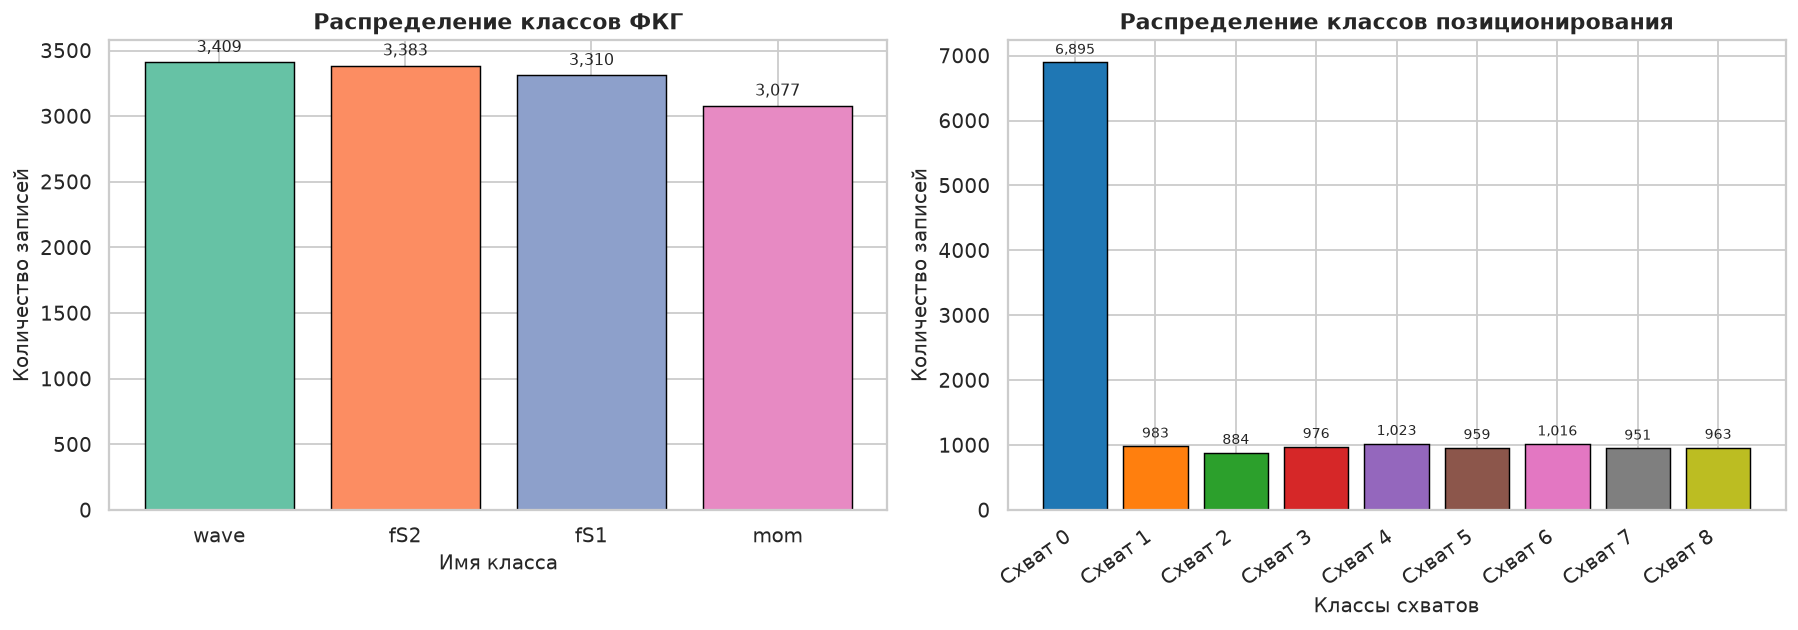

In [6]:
# Ответ на задание 1.1.6: Столбчатая диаграмма количества уникальных классов
plt.savefig("outputs/fkg_classes_distribution.png", dpi=150)
plt.savefig("outputs/pos_classes_distribution.png", dpi=150)
plt.show()


### Задание 1.1.7. Объединение файлов набора ФКГ
Для набора ФКГ объединить все представленные файлы в один единый DataFrame `df_fkg_merged`.


In [7]:
# Ответ на задание 1.1.7: Объединение файлов набора ФКГ в один DataFrame
df_fkg_merged = pd.concat([
    clean_wave[wave_features],
    clean_env[env_features],
    clean_wes[wes_features],
    clean_wave[['Type']]
], axis=1)
print(f"Размерность df_fkg_merged: {df_fkg_merged.shape}")


Размерность df_fkg_merged: (13179, 559)


### Задание 1.1.8. Графики классов ФКГ
Сформировать графики, на которых показаны представленные классы в виде волновой формы, огибающей и энергии вейвлет-преобразования.


Графики сохранены в outputs/fkg_signals_by_class.png


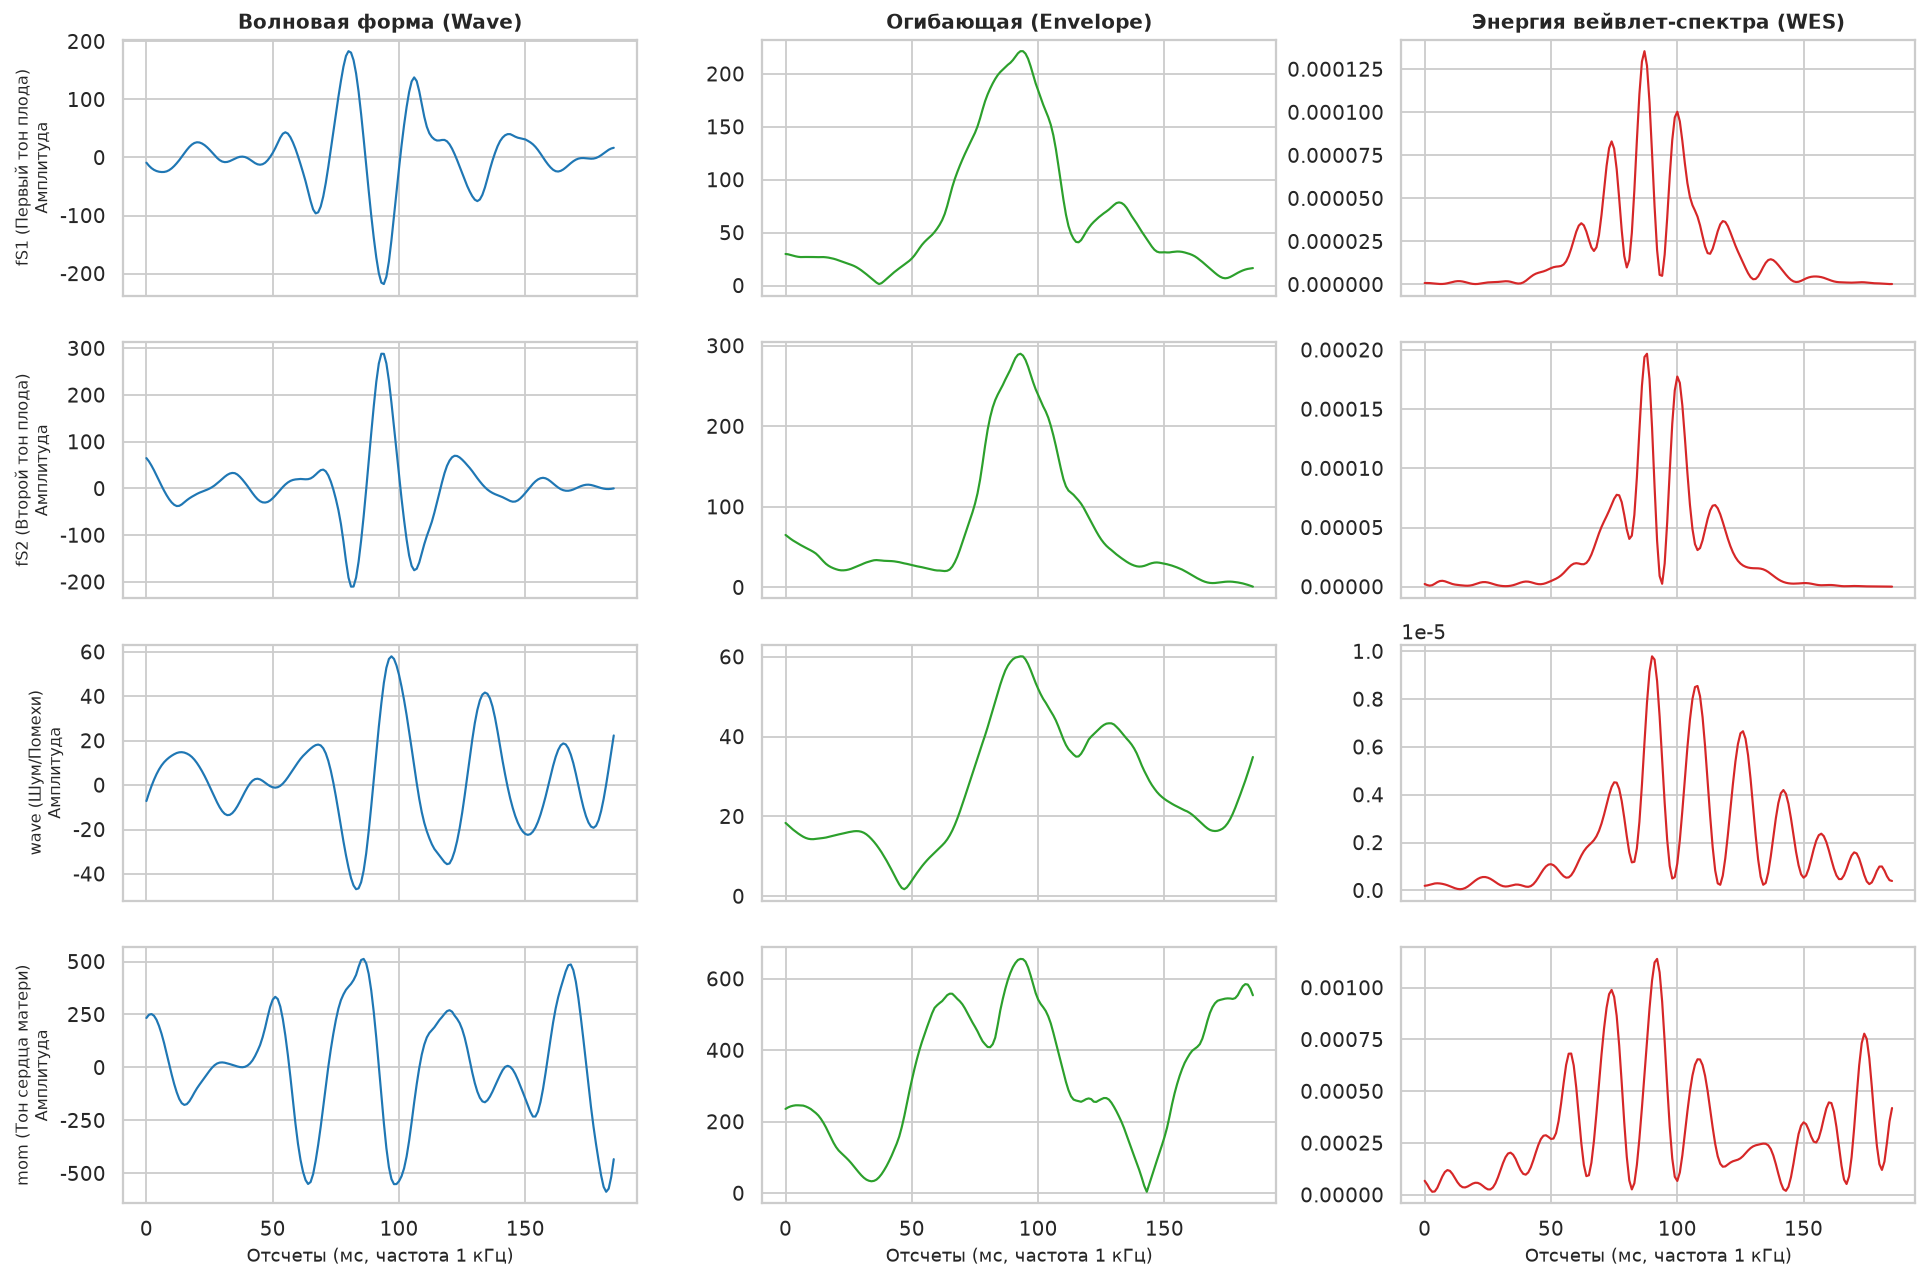

In [8]:
# Ответ на задание 1.1.8: Графики волновой формы, огибающей и вейвлетной энергии ФКГ
plt.savefig("outputs/fkg_signals_by_class.png", dpi=150)
plt.show()


### Задание 1.1.9. Определение количества сенсоров
Информация от скольких инерциально-измерительных сенсоров хранится в наборе данных?


In [9]:
# Ответ на задание 1.1.9: Расчет количества сенсоров модуля позиционирования
# 3432 признака / (3 оси * 104 отсчета) = 11 датчиков
print("В наборе данных модуля позиционирования хранится информация от 11 инерциальных сенсоров.")


Общее количество признаков датчиков: 3432
Осей на датчик: 3 (X, Y, Z)
Отсчетов на ось: 104 (104 Гц)
Количество сенсоров: 3432 / (3 * 104) = 11 датчиков.


### Задание 1.1.10. Графики классов модуля позиционирования
Для каждого из классов набора от модуля позиционирования выведите графики от датчика по трем осям.


Графики сохранены в outputs/pos_sensors_by_class.png


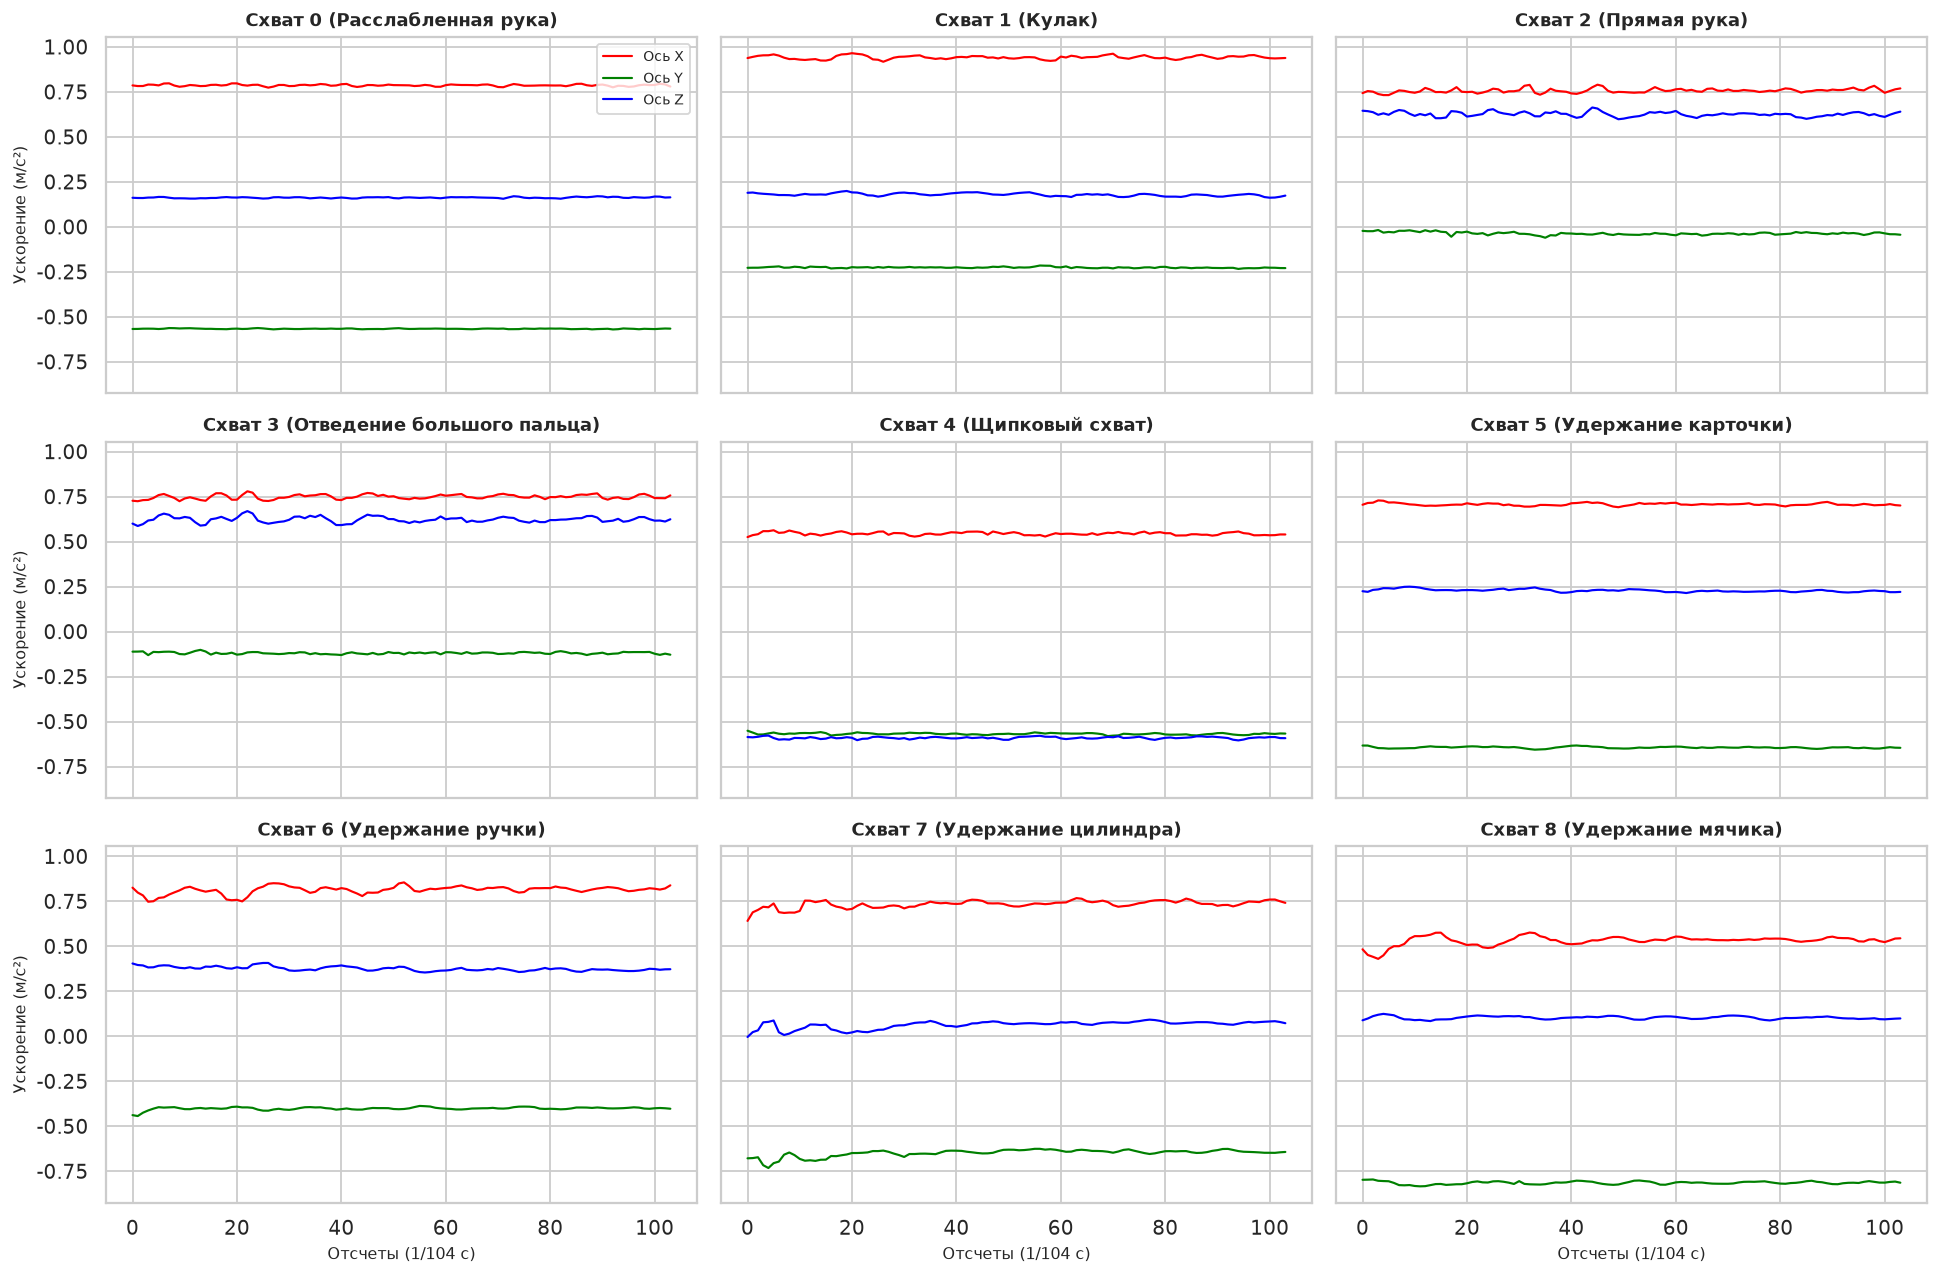

In [10]:
# Ответ на задание 1.1.10: Графики показаний датчика по 3 осям для каждого класса
plt.savefig("outputs/pos_sensors_by_class.png", dpi=150)
plt.show()


### Задания 1.1.11 & 1.1.12. Формирование x_, y_ DataFrames и нормализация
Сформировать DataFrames признаков и меток (4 набора для ФКГ, 1 для позиционирования) и нормализовать их.


In [11]:
# Ответ на задания 1.1.11 и 1.1.12: Формирование x_, y_ и нормализация (StandardScaler)
# Сформировано 4 набора DataFrames для ФКГ и 1 для позиционирования
# Нормализованные данные сохранены в x_fkg_*_norm и x_pos_norm


x_fkg_merged: (13179, 558), x_pos: (14650, 3432)
Нормализация StandardScaler выполнена успешно.


### Задание 1.1.13. Графики нормализованных значений
Вывести на графики нормализованные значения: 3 оси сенсора позиционирования; 3 параметра ФКГ для одного класса.


Графики сохранены в outputs/pos_sensor_normalized_3axes.png и fkg_normalized_single_class_comparison.png


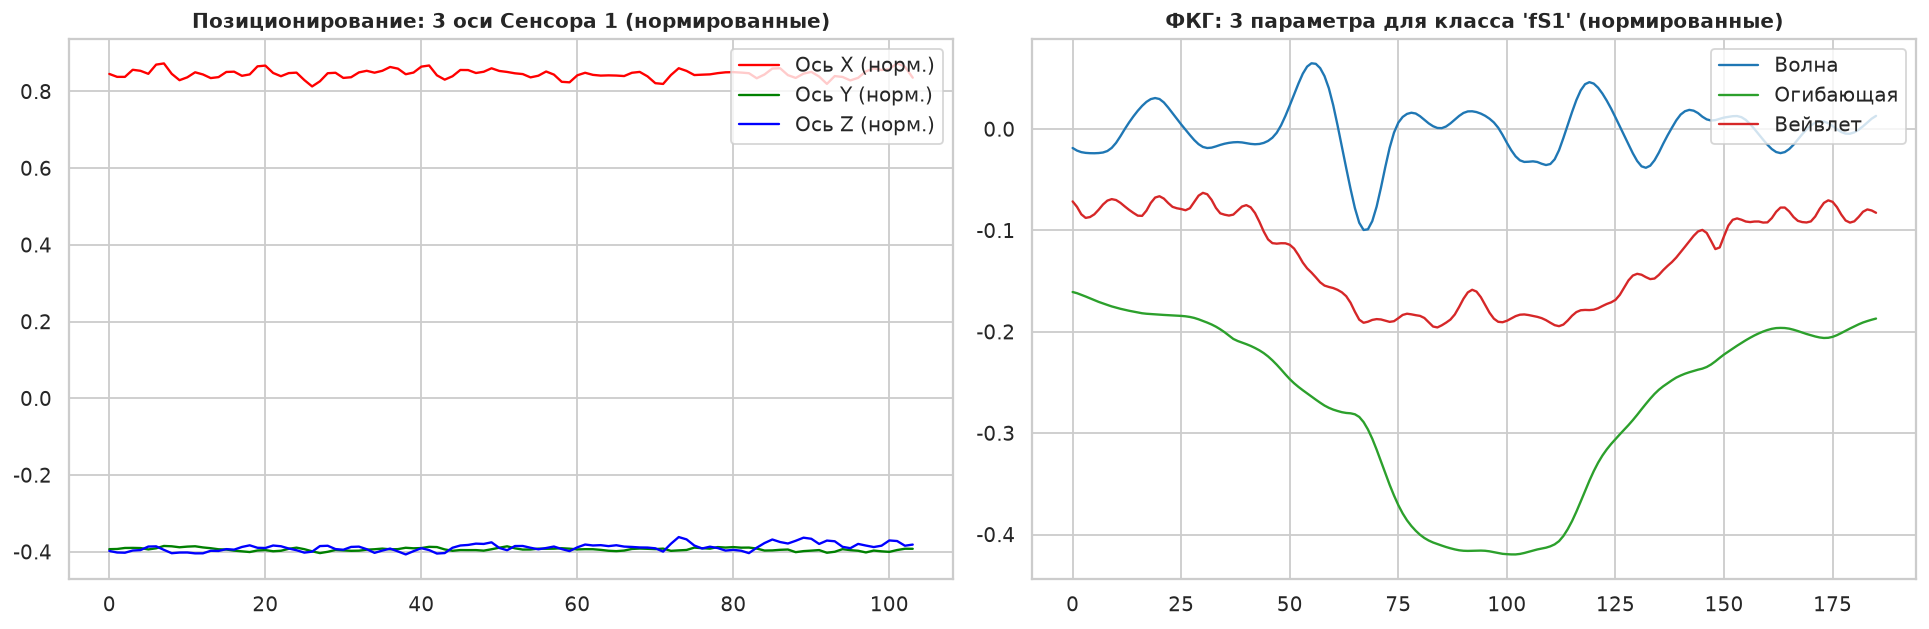

In [12]:
# Ответ на задание 1.1.13: Графики нормализованных сигналов
plt.savefig("outputs/pos_sensor_normalized_3axes.png", dpi=150)
plt.savefig("outputs/fkg_normalized_single_class_comparison.png", dpi=150)
plt.show()
